# Group 2.1 — Tuned vs. Default at n = 100

Compare **5-fold grid-search XGBoost**, **default XGBoost**, and **zero-tuning SmallGBM** on independent test data. The experiment tests whether tuning improves or harms generalization; it does not assume a penalty.

Run all cells with installed `smallgbm`, `xgboost`, `numpy`, `scipy`, `scikit-learn`, `joblib`, `threadpoolctl`, and `matplotlib`. Results are saved under `results/group21/`. Parallel workers run separate trials; XGBoost uses up to two threads per worker. No installation or embedded sources.

In [2]:
import csv
import json
import platform
import time
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t
from sklearn.metrics import roc_auc_score, accuracy_score, log_loss
from sklearn.model_selection import GridSearchCV, StratifiedKFold, ParameterGrid
from joblib import Parallel, delayed, parallel_config, cpu_count
from threadpoolctl import threadpool_limits
from smallgbm import SmallGBMClassifier
from xgboost import XGBClassifier

## 1. Prespecified protocol

Each of three synthetic tasks has 20 independent trials: **100 training rows**, **5,000 independent test rows**, and ten features. All methods share the same data. Five stratified folds contain 80 training and 20 validation rows each. The selected XGBoost is **refitted on all 100 rows**, as are both untuned methods. Test data never select hyperparameters.

The grid includes the default configuration first, followed by 24 alternatives. Ties prefer the default if it ties for the best score. Only seed, CPU device, and thread count are set for default XGBoost; its statistical hyperparameters retain installed library defaults. SmallGBM also uses installed defaults. Versions and fitted XGBoost configurations are saved.

In [3]:
N_TRAIN, N_TEST, D = 100, 5000, 10
SEEDS = (11, 29, 47, 71, 101, 131, 173, 211, 257, 307,
         353, 401, 457, 503, 557, 601, 653, 701, 751, 809)
TASKS = ("Gaussian mixture", "Nonlinear interactions", "Null signal")
METHODS = ("XGBoost default", "XGBoost tuned", "SmallGBM")
METRICS = ("auc", "accuracy", "log_loss")
GRID = [{}, {"max_depth": [2, 3, 6], "learning_rate": [0.03, 0.1],
             "n_estimators": [50, 200], "min_child_weight": [1, 5]}]
N_CANDIDATES = len(list(ParameterGrid(GRID)))
THREADS_PER_WORKER = min(2, cpu_count())
N_WORKERS = min(4, max(1, (cpu_count()-1) // THREADS_PER_WORKER))
assert N_TRAIN == 100 and len(SEEDS) >= 2 and len(SEEDS) == len(set(SEEDS))
assert N_WORKERS * THREADS_PER_WORKER <= cpu_count()

OUT = Path("results/group21") / datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S-%f")
OUT.mkdir(parents=True, exist_ok=False)
(OUT / "trials").mkdir()


def make_xgb(seed):
    return XGBClassifier(random_state=seed, n_jobs=THREADS_PER_WORKER, device="cpu")


def portable(value):
    if isinstance(value, dict):
        return {str(k): portable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [portable(v) for v in value]
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return str(value)
    return value


def save_json(path, value):
    Path(path).write_text(json.dumps(portable(value), indent=2, allow_nan=False), encoding="utf-8")


def write_csv(path, rows):
    if not rows:
        return
    with Path(path).open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

packages = ("numpy", "scipy", "scikit-learn", "smallgbm", "xgboost", "joblib", "threadpoolctl", "matplotlib")
protocol = dict(n_train=N_TRAIN, n_test=N_TEST, d=D, seeds=SEEDS, tasks=TASKS, grid=GRID,
                n_candidates=N_CANDIDATES, cv="StratifiedKFold(5, shuffle=True, random_state=seed)",
                scoring="roc_auc", refit=True, n_workers=N_WORKERS,
                threads_per_worker=THREADS_PER_WORKER,
                versions={p: version(p) for p in packages}, python=platform.python_version(),
                platform=platform.platform(),
                xgb_default_parameters=make_xgb(SEEDS[0]).get_params(),
                smallgbm_parameters=SmallGBMClassifier(random_state=SEEDS[0]).get_params(),
                primary_contrast="default test AUC minus tuned test AUC; positive = tuning penalty",
                intervals="Pointwise 95% t intervals over independent trials, separately per task")
save_json(OUT / "protocol.json", protocol)
# 5 fits per candidate, 1 best refit, 2 untuned models, 10 fold audit refits.
fits_per_trial = 5*N_CANDIDATES + 1 + 2 + 10
print(f"{N_CANDIDATES} candidates; {len(TASKS)*len(SEEDS)} trials; "
      f"{fits_per_trial*len(TASKS)*len(SEEDS)} planned fits (plus RNG checks).")
print(f"CPU budget: {N_WORKERS} processes x {THREADS_PER_WORKER} threads")
print("Package versions:", protocol["versions"])
print("Output:", OUT)

25 candidates; 60 trials; 8280 planned fits (plus RNG checks).
CPU budget: 3 processes x 2 threads
Package versions: {'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'smallgbm': '1.5.0', 'xgboost': '3.4.1', 'joblib': '1.6.0', 'threadpoolctl': '3.8.0', 'matplotlib': '3.11.2'}
Output: results/group21/20261118-072714-786733


## 2. Data and reproducibility

- **Gaussian mixture:** $Y\sim\mathrm{Bernoulli}(0.5)$, $X\mid Y\sim N((2Y-1)\mu,I)$, with $\|\mu\|=1$ and three informative features.
- **Nonlinear interactions:** independent normal features and $Y=1[1.5X_1-X_2+0.8X_3X_4+0.5\epsilon>0]$, $\epsilon\sim N(0,1)$.
- **Null signal:** normal features and independent Bernoulli labels; population test AUC is 0.5. This is a negative control, not a realistic prediction task.

Training and test streams are independent. SmallGBM's native RNG is reset inside each worker; a process backend prevents simultaneous fits from sharing it. The private seeding hook is checked before the benchmark.

In [4]:
def make_data(task, seed):
    streams = np.random.SeedSequence([20261117, TASKS.index(task), seed]).spawn(2)
    mu = np.zeros(D)
    mu[:3] = [1, 0.75, -0.5]
    mu /= np.linalg.norm(mu)

    def draw(n, stream):
        rng = np.random.default_rng(stream)
        X = rng.normal(size=(n, D))
        if task == "Gaussian mixture":
            y = rng.integers(0, 2, n)
            X += (2*y[:, None]-1)*mu
        elif task == "Nonlinear interactions":
            y = (1.5*X[:, 0]-X[:, 1]+0.8*X[:, 2]*X[:, 3]+0.5*rng.normal(size=n) > 0).astype(int)
        elif task == "Null signal":
            y = rng.integers(0, 2, n)
        else:
            raise ValueError(task)
        return np.ascontiguousarray(X), y

    X, y = draw(N_TRAIN, streams[0])
    Xt, yt = draw(N_TEST, streams[1])
    assert np.bincount(y, minlength=2).min() >= 5
    assert np.unique(yt).size == 2
    return X, y, Xt, yt


def seed_smallgbm(seed):
    import ctypes
    from smallgbm import tree as gbm_tree
    try:
        seed_c = gbm_tree._lib.srand
    except AttributeError as exc:
        raise RuntimeError("Review native RNG seeding for this SmallGBM build.") from exc
    seed_c.argtypes = [ctypes.c_uint]
    seed_c.restype = None
    seed_c(int(seed))


def positive_probability(model, X):
    p = np.asarray(model.predict_proba(X)[:, 1])
    assert p.shape == (len(X),) and np.isfinite(p).all()
    assert np.all((p >= 0) & (p <= 1))
    return p


def reproducibility_probe():
    X, y, Xt, _ = make_data(TASKS[0], 999)
    with threadpool_limits(limits=THREADS_PER_WORKER):
        seed_smallgbm(999)
        model = SmallGBMClassifier(random_state=999).fit(X, y)
        return positive_probability(model, Xt[:100])

a = reproducibility_probe()
with parallel_config(backend="loky", n_jobs=N_WORKERS,
                     inner_max_num_threads=THREADS_PER_WORKER):
    probes = Parallel()(delayed(reproducibility_probe)() for _ in range(2))
assert all(np.array_equal(a, p) for p in probes), "Native RNG is not reproducible."
print("SmallGBM sequential/parallel reproducibility check passed.")

SmallGBM sequential/parallel reproducibility check passed.


## 3. Search, full-data refit, and fold audit

Selection uses mean validation AUC on the same five folds for every candidate. Each trial saves all candidate scores, selected parameters, fold indices, data, and predictions. Any failed trial blocks summary generation.

After selection, a diagnostic refits the default and selected configurations on each original **80-row** training fold, then evaluates them on the independent test set. This estimates their test AUC at the same training size as CV. Differential CV optimism is:

$$ (CV_{selected}-CV_{default})-(Test^{80}_{selected}-Test^{80}_{default}). $$

Positive values indicate that the CV tuning gain exceeds the independent-test gain at matched training size. This is a diagnostic, not a causal decomposition. The primary comparison remains the three models trained on all 100 rows. No audit result changes the chosen configuration.

In [5]:
def trial_impl(task, seed, output_dir):
    trial_dir = Path(output_dir) / "trials" / f"task{TASKS.index(task)}_seed{seed}"
    trial_dir.mkdir()
    X, y, Xt, yt = make_data(task, seed)
    folds = list(StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y))
    assert all(len(train) == 80 and len(valid) == 20 and not set(train) & set(valid)
               for train, valid in folds)
    fold_ids = np.empty(N_TRAIN, dtype=int)
    for k, (_, valid) in enumerate(folds):
        fold_ids[valid] = k
    np.savez_compressed(trial_dir / "data.npz", X_train=X, y_train=y, X_test=Xt, y_test=yt,
                        validation_fold=fold_ids)

    start = time.perf_counter()
    search = GridSearchCV(make_xgb(seed), GRID, scoring="roc_auc", cv=folds,
                          refit=True, n_jobs=1, error_score="raise", return_train_score=False)
    search.fit(X, y)
    search_seconds = time.perf_counter()-start
    cv = search.cv_results_
    assert cv["params"][0] == {} and np.isfinite(cv["mean_test_score"]).all()
    assert search.best_score_ >= cv["mean_test_score"][0]-1e-12
    candidate_rows = []
    for j, params in enumerate(cv["params"]):
        row = dict(task=task, seed=seed, candidate=j, params=json.dumps(params, sort_keys=True),
                   cv_auc=float(cv["mean_test_score"][j]), cv_fold_sd=float(cv["std_test_score"][j]),
                   selected=int(j == search.best_index_))
        row.update({f"fold{k}_auc": float(cv[f"split{k}_test_score"][j]) for k in range(5)})
        candidate_rows.append(row)
    write_csv(trial_dir / "candidates.csv", candidate_rows)

    default = make_xgb(seed)
    start = time.perf_counter(); default.fit(X, y)
    default_seconds = time.perf_counter()-start
    small = SmallGBMClassifier(random_state=seed)
    seed_smallgbm(seed)
    start = time.perf_counter(); small.fit(X, y)
    small_seconds = time.perf_counter()-start
    models = {METHODS[0]: default, METHODS[1]: search.best_estimator_, METHODS[2]: small}
    seconds = {METHODS[0]: default_seconds, METHODS[1]: search_seconds, METHODS[2]: small_seconds}
    predictions = {}
    results = []
    for name, model in models.items():
        p = positive_probability(model, Xt)
        predictions[name] = p
        results.append(dict(task=task, seed=seed, method=name,
                            auc=float(roc_auc_score(yt, p)),
                            accuracy=float(accuracy_score(yt, p > 0.5)),
                            log_loss=float(log_loss(yt, np.column_stack((1-p, p)), labels=[0, 1])),
                            seconds=seconds[name]))

    audit = []
    audit_predictions = {"default": [], "selected": []}
    for k, (train, valid) in enumerate(folds):
        for kind, params in (("default", {}), ("selected", search.best_params_)):
            model = make_xgb(seed).set_params(**params).fit(X[train], y[train])
            p = positive_probability(model, Xt)
            audit_predictions[kind].append(p)
            validation_auc = roc_auc_score(y[valid], positive_probability(model, X[valid]))
            j = 0 if kind == "default" else search.best_index_
            assert np.isclose(validation_auc, cv[f"split{k}_test_score"][j], atol=1e-12, rtol=0), \
                "Fold refit did not reproduce its original validation score."
            audit.append(dict(task=task, seed=seed, fold=k, configuration=kind,
                              validation_auc=float(validation_auc), external_auc=float(roc_auc_score(yt, p))))
    default_80 = np.mean([r["external_auc"] for r in audit if r["configuration"] == "default"])
    selected_80 = np.mean([r["external_auc"] for r in audit if r["configuration"] == "selected"])
    scores = {r["method"]: r["auc"] for r in results}
    cv_default = float(cv["mean_test_score"][0])
    cv_selected = float(search.best_score_)
    diagnostic = dict(task=task, seed=seed, best_candidate=int(search.best_index_),
                      best_params=json.dumps(search.best_params_, sort_keys=True),
                      default_cv_auc=cv_default, selected_cv_auc=cv_selected,
                      default_test80_auc=float(default_80), selected_test80_auc=float(selected_80),
                      cv_gain=cv_selected-cv_default, test80_gain=float(selected_80-default_80),
                      differential_cv_optimism=float((cv_selected-cv_default)-(selected_80-default_80)),
                      tuning_penalty=scores[METHODS[0]]-scores[METHODS[1]],
                      smallgbm_minus_tuned=scores[METHODS[2]]-scores[METHODS[1]],
                      selected_cv_minus_test100=cv_selected-scores[METHODS[1]],
                      default_test100_minus_test80=float(scores[METHODS[0]]-default_80),
                      search_seconds=search_seconds, refit_seconds=float(search.refit_time_),
                      train_positives=int(y.sum()), test_positives=int(yt.sum()))
    np.savez_compressed(trial_dir / "predictions.npz", default=predictions[METHODS[0]],
                        tuned=predictions[METHODS[1]], smallgbm=predictions[METHODS[2]],
                        default_fold=np.array(audit_predictions["default"]),
                        selected_fold=np.array(audit_predictions["selected"]))
    save_json(trial_dir / "selection.json", diagnostic)
    save_json(trial_dir / "resolved_xgboost.json",
              {"default": json.loads(default.get_booster().save_config()),
               "selected": json.loads(search.best_estimator_.get_booster().save_config())})
    return dict(status="ok", task=task, seed=seed, error="", results=results,
                diagnostic=diagnostic, candidates=candidate_rows, audit=audit)


def run_trial(task, seed, output_dir):
    try:
        with threadpool_limits(limits=THREADS_PER_WORKER):
            return trial_impl(task, seed, output_dir)
    except Exception as exc:
        return dict(status="error", task=task, seed=seed, error=f"{type(exc).__name__}: {exc}")

runs, diagnostics, candidates, audit_rows, statuses = [], [], [], [], []
started = time.perf_counter()
with parallel_config(backend="loky", n_jobs=N_WORKERS,
                     inner_max_num_threads=THREADS_PER_WORKER):
    stream = Parallel(return_as="generator_unordered")(
        delayed(run_trial)(task, seed, str(OUT)) for task in TASKS for seed in SEEDS)
    for batch in stream:
        statuses.append({key: batch[key] for key in ("task", "seed", "status", "error")})
        if batch["status"] == "ok":
            runs.extend(batch["results"]); diagnostics.append(batch["diagnostic"])
            candidates.extend(batch["candidates"]); audit_rows.extend(batch["audit"])
        for filename, data in (("runs", runs), ("diagnostics", diagnostics),
                               ("candidates", candidates), ("fold_audit", audit_rows), ("status", statuses)):
            data.sort(key=lambda r: (TASKS.index(r["task"]), r["seed"]))
            write_csv(OUT / f"{filename}.csv", data)
        print(f"Completed {len(statuses)}/{len(TASKS)*len(SEEDS)} trials", flush=True)
assert len(statuses) == len(TASKS)*len(SEEDS)
failed = [r for r in statuses if r["status"] != "ok"]
assert not failed, f"Failed trials: {failed}. Inspect status.csv; do not summarize incomplete results."
protocol["wall_seconds"] = time.perf_counter()-started
save_json(OUT / "protocol.json", protocol)
print(f"All trials passed in {protocol['wall_seconds']:.1f} seconds.")

Completed 1/60 trials
Completed 2/60 trials
Completed 3/60 trials
Completed 4/60 trials
Completed 5/60 trials
Completed 6/60 trials
Completed 7/60 trials
Completed 8/60 trials
Completed 9/60 trials
Completed 10/60 trials
Completed 11/60 trials
Completed 12/60 trials
Completed 13/60 trials
Completed 14/60 trials
Completed 15/60 trials
Completed 16/60 trials
Completed 17/60 trials
Completed 18/60 trials
Completed 19/60 trials
Completed 20/60 trials
Completed 21/60 trials
Completed 22/60 trials
Completed 23/60 trials
Completed 24/60 trials
Completed 25/60 trials
Completed 26/60 trials
Completed 27/60 trials
Completed 28/60 trials
Completed 29/60 trials
Completed 30/60 trials
Completed 31/60 trials
Completed 32/60 trials
Completed 33/60 trials
Completed 34/60 trials
Completed 35/60 trials
Completed 36/60 trials
Completed 37/60 trials
Completed 38/60 trials
Completed 39/60 trials
Completed 40/60 trials
Completed 41/60 trials
Completed 42/60 trials
Completed 43/60 trials
Completed 44/60 tria

## 4. Test performance and diagnostic intervals

Report tasks separately. Bands/error bars are pointwise 95% t intervals across independent trials, not across the five dependent CV folds. **Positive tuning penalty = default test AUC exceeds tuned test AUC.** Negative values mean tuning helps. Confidence intervals crossing zero are inconclusive at this precision; no winner is forced.

The selected-CV minus full-refit-test gap mixes selection effects with training-size effects. Use the matched-80-row diagnostic alongside it, without equating either gap to a proof of Equation 4. Timings include the entire search for tuned XGBoost and are collected under concurrent load.

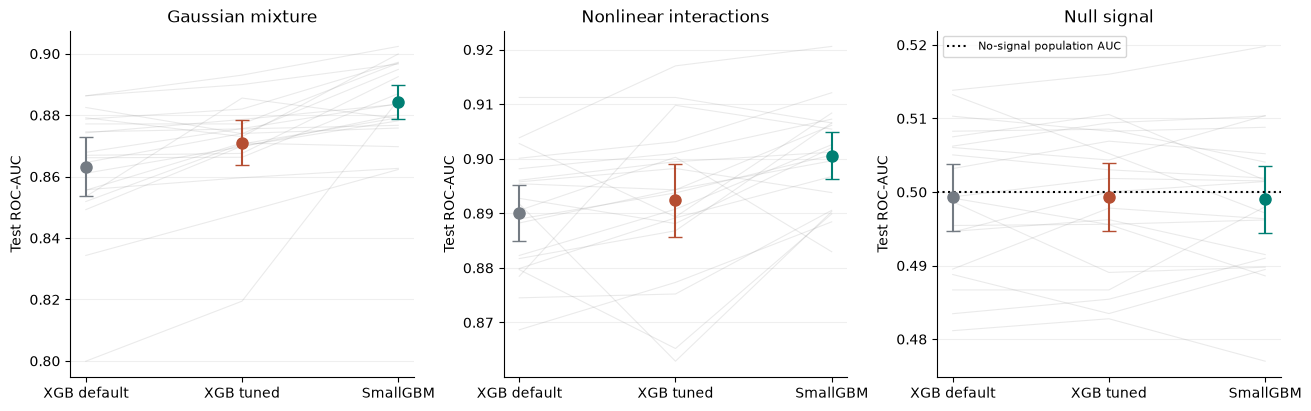

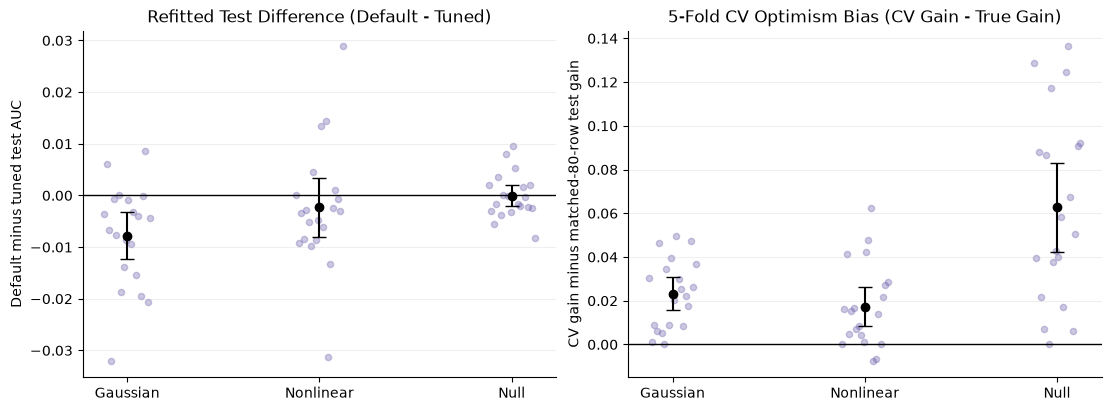

Mean test ROC-AUC:
Gaussian mixture
  XGBoost default  : 0.8633 [0.8538, 0.8728]
  XGBoost tuned    : 0.8710 [0.8637, 0.8784]
  SmallGBM         : 0.8842 [0.8787, 0.8897]
  Default minus tuned: -0.0078 [-0.0124, -0.0031]; tuning improvement observed.
Nonlinear interactions
  XGBoost default  : 0.8900 [0.8849, 0.8951]
  XGBoost tuned    : 0.8924 [0.8857, 0.8990]
  SmallGBM         : 0.9006 [0.8963, 0.9049]
  Default minus tuned: -0.0023 [-0.0080, +0.0033]; inconclusive mean difference.
Null signal
  XGBoost default  : 0.4993 [0.4947, 0.5038]
  XGBoost tuned    : 0.4993 [0.4947, 0.5039]
  SmallGBM         : 0.4990 [0.4945, 0.5035]
  Default minus tuned: -0.0001 [-0.0021, +0.0020]; inconclusive mean difference.
Results: results/group21/20261118-072714-786733


In [6]:
def mean_ci(values):
    a = np.asarray(values, dtype=float)
    assert len(a) == len(SEEDS) and np.isfinite(a).all()
    mean = float(a.mean())
    half = float(t.ppf(0.975, len(a)-1)*a.std(ddof=1)/np.sqrt(len(a)))
    return mean, mean-half, mean+half

summary = []
for task in TASKS:
    for method in METHODS:
        selected = [r for r in runs if r["task"] == task and r["method"] == method]
        for metric in METRICS:
            mean, lo, hi = mean_ci([r[metric] for r in selected])
            summary.append(dict(task=task, method=method, metric=metric,
                                mean=mean, ci_low=lo, ci_high=hi, trials=len(SEEDS)))
write_csv(OUT / "summary.csv", summary)

DIAGNOSTIC_NAMES = ("tuning_penalty", "smallgbm_minus_tuned", "cv_gain", "test80_gain",
                    "differential_cv_optimism", "selected_cv_minus_test100", "default_test100_minus_test80")
diag_summary = []
for task in TASKS:
    for metric in DIAGNOSTIC_NAMES:
        mean, lo, hi = mean_ci([r[metric] for r in diagnostics if r["task"] == task])
        diag_summary.append(dict(task=task, metric=metric, mean=mean, ci_low=lo, ci_high=hi,
                                 trials=len(SEEDS)))
write_csv(OUT / "diagnostic_summary.csv", diag_summary)

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
colors = {METHODS[0]: "#747b83", METHODS[1]: "#b54e32", METHODS[2]: "#007f73"}

# --- ГРАФИК 1: Test AUC ---
fig, axes = plt.subplots(1, len(TASKS), figsize=(13, 4), constrained_layout=True)
for ax, task in zip(axes, TASKS):
    for seed in SEEDS:
        values = [next(r["auc"] for r in runs if r["task"] == task and r["seed"] == seed
                       and r["method"] == method) for method in METHODS]
        ax.plot(range(3), values, color="gray", alpha=0.16, linewidth=0.8)
    for i, method in enumerate(METHODS):
        r = next(r for r in summary if r["task"] == task and r["method"] == method and r["metric"] == "auc")
        ax.errorbar(i, r["mean"], yerr=[[r["mean"]-r["ci_low"]], [r["ci_high"]-r["mean"]]],
                    fmt="o", color=colors[method], capsize=5, markersize=8)
    if task == "Null signal":
        ax.axhline(0.5, color="black", linestyle=":", label="No-signal population AUC")
        ax.legend(fontsize=8)
    ax.set(xticks=range(3), xticklabels=("XGB default", "XGB tuned", "SmallGBM"),
           ylabel="Test ROC-AUC", title=task)
    ax.grid(axis="y", alpha=0.2)
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"test_auc.{ext}", dpi=180)
plt.show()

# --- ГРАФИК 2: Diagnostics (С ИСПРАВЛЕННЫМИ ЗАГОЛОВКАМИ) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, metric, title, ylabel in (
    (axes[0], "tuning_penalty", "Refitted Test Difference (Default - Tuned)", "Default minus tuned test AUC"),
    (axes[1], "differential_cv_optimism", "5-Fold CV Optimism Bias (CV Gain - True Gain)", "CV gain minus matched-80-row test gain")):
    for i, task in enumerate(TASKS):
        vals = [r[metric] for r in diagnostics if r["task"] == task]
        r = next(r for r in diag_summary if r["task"] == task and r["metric"] == metric)
        ax.scatter(i+np.linspace(-0.12, 0.12, len(vals)), vals, alpha=0.35, s=20, color="#6e62ad")
        ax.errorbar(i, r["mean"], yerr=[[r["mean"]-r["ci_low"]], [r["ci_high"]-r["mean"]]],
                    fmt="o", color="black", capsize=5)
    ax.axhline(0, color="black", linewidth=1)
    ax.set(xticks=range(len(TASKS)), xticklabels=("Gaussian", "Nonlinear", "Null"),
           ylabel=ylabel, title=title)
    ax.grid(axis="y", alpha=0.2)
for ext in ("png", "pdf"):
    fig.savefig(OUT / f"tuning_diagnostics.{ext}", dpi=180)
plt.show()

print("Mean test ROC-AUC:")
for task in TASKS:
    print(task)
    for method in METHODS:
        r = next(r for r in summary if r["task"] == task and r["method"] == method and r["metric"] == "auc")
        print(f"  {method:17s}: {r['mean']:.4f} [{r['ci_low']:.4f}, {r['ci_high']:.4f}]")
    r = next(r for r in diag_summary if r["task"] == task and r["metric"] == "tuning_penalty")
    verdict = "tuning penalty observed" if r["ci_low"] > 0 else (
        "tuning improvement observed" if r["ci_high"] < 0 else "inconclusive mean difference")
    print(f"  Default minus tuned: {r['mean']:+.4f} [{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]; {verdict}.")
print("Results:", OUT)

## Reporting limits

This benchmark tests a fixed search procedure at $n=100$ on two learnable synthetic distributions and a null control. Keep every trial and report improvements as well as penalties. The defaults, grid, datasets, and seeds must not be changed in response to test outcomes.

Five-fold CV temporarily trains on 80 rows per fit; `refit=True` restores all 100 rows for the final model. Consequently, this experiment cannot demonstrate permanent training-data depletion. A finite-grid deviation bound such as Equation 4 describes potential estimation error under its assumptions; it does not imply that tuning must harm generalization. Varying grid size and sample size would be a separate experiment.

References: [GridSearchCV and refit semantics](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), [scikit-learn model-selection guidance](https://scikit-learn.org/stable/modules/grid_search.html), [SmallGBM](https://github.com/nsdmlk/SmallGBM).